<a href="https://colab.research.google.com/github/Andrian0s/ML4NLP1-2026-Tutorial-Notebooks/blob/main/tutorials_notebooks_in_class_2026/W06_similarity_analogy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The following additional library is needed to run this notebook.

In [ ]:
%pip install -q gensim==4.4.0

# Word Similarity and Analogy

In Exercise 2, you train a CBOW (word2vec) model on a small dataset and use it to find semantically similar words for an input word. In practice, word vectors that are pretrained on large corpora are often used instead, for example as input for downstream natural language processing tasks. In this tutorial, we take such pretrained vectors (GloVe) and look at four questions:

1. How do static word embeddings work?
2. Which relations between words do they capture (word similarity and analogy)?
3. How can we check the quality of word embeddings?
4. What are their limitations?

In [2]:
import contextlib
import io

import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import gensim.downloader as api
from gensim.test.utils import datapath

## Loading Pretrained Word Vectors

The following examples are mostly based on [this chapter on similarity and analogy in NLP](https://d2l.ai/chapter_natural-language-processing-pretraining/similarity-analogy.html) with additions by Michelle Wastl.

We use the pretrained GloVe embeddings *glove.6B* from the [GloVe website](https://nlp.stanford.edu/projects/glove/). They were trained on Wikipedia (2014) and the Gigaword newswire corpus, about 6 billion tokens in total. The vocabulary contains the 400,000 most frequent words, all lowercased, and the vectors are available with 50, 100, 200 and 300 dimensions.

Below we load the 50- and 100-dimensional vectors with `gensim.downloader`. The first run downloads them (66 MB and 134 MB) and caches them, which takes about half a minute.

In [3]:
print('Loading GloVe 50d and 100d (the first run downloads ~200 MB)...')
with contextlib.redirect_stdout(io.StringIO()):  # hide gensim's very chatty progress bar
    glove_6b50d = api.load('glove-wiki-gigaword-50')    # same vectors as glove.6B.50d
    glove_6b100d = api.load('glove-wiki-gigaword-100')  # same vectors as glove.6B.100d
print('Done.')

Loading GloVe 50d and 100d (the first run downloads ~200 MB)...


Done.


## How Static Word Embeddings Work

A static word embedding model is a lookup table with one row per word in the vocabulary. For `glove_6b50d`, the table has 400,000 rows and 50 columns. The rows are sorted by word frequency, so the row index of a word is also its frequency rank.

In [4]:
print(glove_6b50d.vectors.shape)              # (number of words, number of dimensions)
print(glove_6b50d.key_to_index['beautiful'])  # row index of a word = its frequency rank
glove_6b50d['beautiful']                      # the row itself: the 50-dimensional vector of the word

(400000, 50)
3366


array([ 0.54623  ,  1.2042   , -1.1288   , -0.1325   ,  0.95529  ,
        0.040524 , -0.47863  , -0.3397   , -0.28056  ,  0.71761  ,
       -0.53691  , -0.0045698,  0.73217  ,  0.12101  ,  0.28093  ,
       -0.088097 ,  0.59733  ,  0.55264  ,  0.056646 , -0.50247  ,
       -0.63204  ,  1.1439   , -0.31053  ,  0.1263   ,  1.3155   ,
       -0.52444  , -1.5041   ,  1.158    ,  0.68795  , -0.85051  ,
        2.3236   , -0.41789  ,  0.44519  , -0.019216 ,  0.28969  ,
        0.53258  , -0.023008 ,  0.58958  , -0.72397  , -0.85216  ,
       -0.17761  ,  0.14432  ,  0.40658  , -0.52003  ,  0.09081  ,
        0.082961 , -0.021975 , -1.6214   ,  0.34579  , -0.010919 ],
      dtype=float32)

Where do the numbers come from? Both word2vec and GloVe build on the *distributional hypothesis*: words that occur in similar contexts tend to have similar meanings.

**word2vec** (CBOW and skip-gram) slides a small window over the text and trains the vectors to predict a word from its context words (CBOW) or the context words from the word (skip-gram). In PyTorch, the table is the weight matrix of an `nn.Embedding` layer.

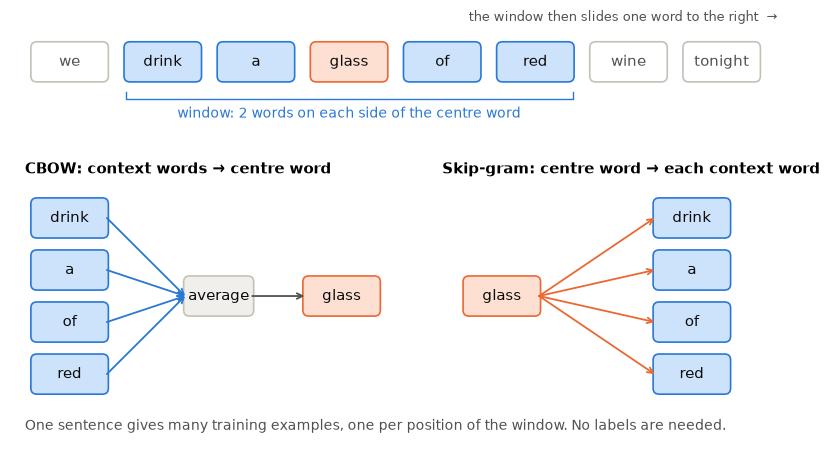

In [5]:
# @title Diagram: training examples for word2vec
from matplotlib.patches import FancyBboxPatch

def word_box(ax, x, y, text, kind='other', w=1.0, h=0.5):
    face, edge, color = {'center': ('#fde0d2', '#eb6834', '#0b0b0b'), 'context': ('#cde2fb', '#2a78d6', '#0b0b0b'),
                         'other': ('white', '#c3c2b7', '#52514e'), 'op': ('#f0efec', '#c3c2b7', '#0b0b0b')}[kind]
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.02,rounding_size=0.08',
                                facecolor=face, edgecolor=edge, lw=1.2))
    ax.text(x, y, text, ha='center', va='center', color=color, fontsize=11)

def arrow(ax, start, end, color='#52514e'):
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(arrowstyle='->', color=color, lw=1.3, shrinkA=0, shrinkB=0))

tokens = ['we', 'drink', 'a', 'glass', 'of', 'red', 'wine', 'tonight']
center, window = 3, 2
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.set_xlim(-0.2, 10.2)
ax.set_ylim(-0.4, 5.4)
ax.axis('off')

# the sentence with a window of +-2 around the centre word
for i, token in enumerate(tokens):
    kind = 'center' if i == center else 'context' if abs(i - center) <= window else 'other'
    word_box(ax, 0.6 + i * 1.25, 4.7, token, kind)
x_left, x_right = 0.6 + (center - window) * 1.25 - 0.5, 0.6 + (center + window) * 1.25 + 0.5
ax.plot([x_left, x_left, x_right, x_right], [4.3, 4.2, 4.2, 4.3], color='#2a78d6', lw=1)
ax.text((x_left + x_right) / 2, 3.95, 'window: 2 words on each side of the centre word', ha='center', color='#2a78d6')
ax.text(10.1, 5.25, 'the window then slides one word to the right  →', ha='right', color='#52514e', fontsize=9)

context = [tokens[i] for i in range(center - window, center + window + 1) if i != center]
# CBOW: context words -> average -> centre word
ax.text(0.0, 3.2, 'CBOW: context words → centre word', fontsize=11, fontweight='bold')
ys = [2.6, 1.9, 1.2, 0.5]
for y, token in zip(ys, context):
    word_box(ax, 0.6, y, token, 'context')
    arrow(ax, (1.1, y), (2.15, 1.55), '#2a78d6')
word_box(ax, 2.6, 1.55, 'average', 'op', w=0.9)
arrow(ax, (3.05, 1.55), (3.75, 1.55))
word_box(ax, 4.25, 1.55, tokens[center], 'center')

# skip-gram: centre word -> each context word separately
ax.text(5.6, 3.2, 'Skip-gram: centre word → each context word', fontsize=11, fontweight='bold')
word_box(ax, 6.4, 1.55, tokens[center], 'center')
for y, token in zip(ys, context):
    arrow(ax, (6.9, 1.55), (8.45, y), '#eb6834')
    word_box(ax, 8.95, y, token, 'context')
ax.text(0.0, -0.25, 'One sentence gives many training examples, one per position of the window. No labels are needed.', color='#52514e')
plt.show()

**GloVe** first counts how often every two words occur near each other in the whole corpus. It then learns two vectors for every word, one for the word itself and one for the word as a context of other words, so that for each pair of words the dot product of the first word's vector and the second word's context vector (plus two bias terms) approximates the logarithm of their co-occurrence count. The embedding of a word is the sum of its two vectors. A toy example:

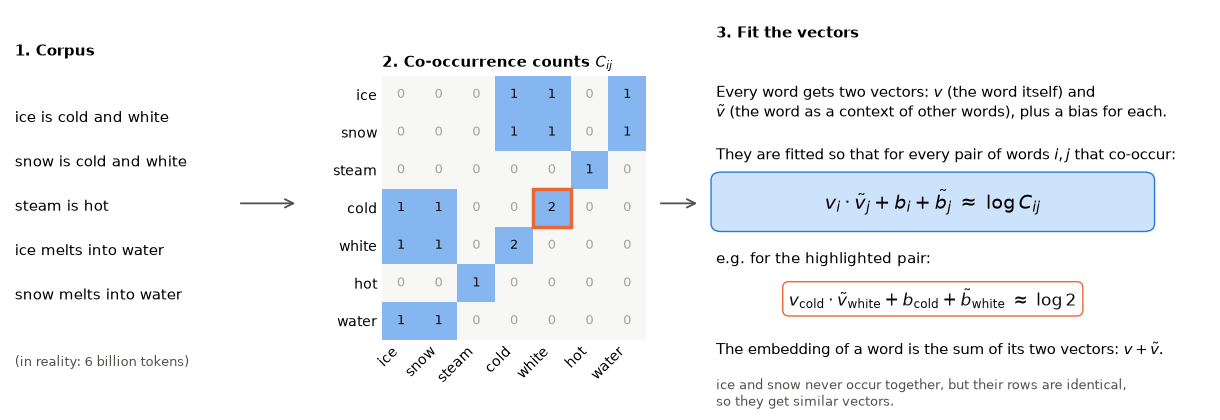

In [6]:
# @title Diagram: how GloVe is trained
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle

corpus = ['ice is cold and white', 'snow is cold and white', 'steam is hot', 'ice melts into water', 'snow melts into water']
words = ['ice', 'snow', 'steam', 'cold', 'white', 'hot', 'water']
counts = np.zeros((len(words), len(words)), dtype=int)
for sentence in corpus:  # here the window is the whole (short) sentence
    present = [w for w in sentence.split() if w in words]
    for w1 in present:
        for w2 in present:
            if w1 != w2:
                counts[words.index(w1), words.index(w2)] += 1

fig = plt.figure(figsize=(12, 4.4))
ax_text = fig.add_axes([0.0, 0.08, 0.2, 0.84]); ax_text.axis('off')
ax_counts = fig.add_axes([0.31, 0.16, 0.22, 0.66])
ax_fit = fig.add_axes([0.58, 0.04, 0.42, 0.9]); ax_fit.axis('off')

# 1. corpus
ax_text.text(0.02, 0.9, '1. Corpus', fontsize=11, fontweight='bold', transform=ax_text.transAxes)
for i, sentence in enumerate(corpus):
    ax_text.text(0.02, 0.72 - i * 0.12, sentence, fontsize=11, transform=ax_text.transAxes)
ax_text.text(0.02, 0.06, '(in reality: 6 billion tokens)', fontsize=9, color='#52514e', transform=ax_text.transAxes)

# 2. counts, with the pair (cold, white) highlighted
ax_counts.imshow(counts, cmap=ListedColormap(['#f7f7f5', '#86b6ef']), vmin=0, vmax=1)
for i in range(len(words)):
    for j in range(len(words)):
        ax_counts.text(j, i, counts[i, j], ha='center', va='center', fontsize=9, color='#0b0b0b' if counts[i, j] else '#a5a49d')
i_cold, j_white = words.index('cold'), words.index('white')
ax_counts.add_patch(Rectangle((j_white - 0.5, i_cold - 0.5), 1, 1, fill=False, edgecolor='#eb6834', lw=2.5))
ax_counts.set_xticks(range(len(words)), words, rotation=45, ha='right')
ax_counts.set_yticks(range(len(words)), words)
ax_counts.tick_params(length=0)
ax_counts.spines[:].set_visible(False)
ax_counts.set_title('2. Co-occurrence counts $C_{ij}$', loc='left', fontsize=11, fontweight='bold')

# 3. fit two vectors per word
t = ax_fit.transAxes
ax_fit.text(0.02, 0.93, '3. Fit the vectors', fontsize=11, fontweight='bold', transform=t)
ax_fit.text(0.02, 0.73, 'Every word gets two vectors: $v$ (the word itself) and\n'
            r'$\tilde{v}$ (the word as a context of other words), plus a bias for each.', fontsize=10.5, transform=t)
ax_fit.text(0.02, 0.62, 'They are fitted so that for every pair of words $i, j$ that co-occur:', fontsize=10.5, transform=t)
ax_fit.add_patch(FancyBboxPatch((0.02, 0.45), 0.86, 0.13, boxstyle='round,pad=0.01,rounding_size=0.02',
                                facecolor='#cde2fb', edgecolor='#2a78d6', transform=t))
ax_fit.text(0.45, 0.515, r'$v_i \cdot \tilde{v}_j + b_i + \tilde{b}_j \;\approx\; \log C_{ij}$', fontsize=14, ha='center', va='center', transform=t)
ax_fit.text(0.02, 0.36, 'e.g. for the highlighted pair:', fontsize=10.5, transform=t)
ax_fit.text(0.45, 0.27, r'$v_{\mathrm{cold}} \cdot \tilde{v}_{\mathrm{white}} + b_{\mathrm{cold}} + \tilde{b}_{\mathrm{white}} \;\approx\; \log 2$',
            fontsize=12.5, ha='center', va='center', color='#0b0b0b', transform=t,
            bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='#eb6834'))
ax_fit.text(0.02, 0.13, r'The embedding of a word is the sum of its two vectors: $v + \tilde{v}$.', fontsize=10.5, transform=t)
ax_fit.text(0.02, 0.0, 'ice and snow never occur together, but their rows are identical,\nso they get similar vectors.',
            fontsize=9, color='#52514e', transform=t)

for x0, x1 in [(0.19, 0.24), (0.54, 0.575)]:
    fig.add_artist(FancyArrowPatch((x0, 0.5), (x1, 0.5), transform=fig.transFigure,
                                   arrowstyle='->', mutation_scale=15, color='#52514e', lw=1.3))
plt.show()

Either way, the result is one fixed vector per word, regardless of the sentence in which the word occurs. This is why these embeddings are called *static*.

## What Do the Vectors Capture?

Using the loaded GloVe vectors, we will demonstrate their semantics by applying them in the following word similarity and analogy tasks.

### Word Similarity

To find semantically similar words for an input word, we rank all words in the vocabulary by the cosine similarity between their vectors and the vector of the input word. We implement this in the following `knn` ($k$-nearest neighbours) function.

$$ \cos(\theta) = \frac{\mathbf{a} \cdot \mathbf{b}}{|\mathbf{a}| |\mathbf{b}|} $$


$\mathbf{a} \cdot \mathbf{b}$ is the dot product of vectors
a and b. $|\mathbf{a}|$ and $|\mathbf{b}|$ represent the magnitudes of vectors $\mathbf{a}$ and $\mathbf{b}$.

Cosine similarity lies between −1 and 1 and depends only on the angle between the two vectors, not on their lengths.

In [7]:
def knn(W, x, k):
    # Add 1e-9 for numerical stability
    cos = torch.mv(W, x.reshape(-1)) / (
        torch.sqrt(torch.sum(W * W, axis=1) + 1e-9) *
        torch.sqrt((x * x).sum()))
    top_cos, topk = torch.topk(cos, k=k)  # the k largest similarities and their indices
    return topk, top_cos

Demonstrating torch.mv functionality: Dot product b/w rows of Matrix m and a vector v

In [8]:
A = torch.tensor([[1,2,3,4],[5,6,7,8]])
b = torch.tensor([9,10,11,12])
result = torch.mv(A, b)
result # tensor([110, 278])
# 110 = 1*9 + 2*10 + 3*11 + 4*12
# 278 = 5*9 + 6*10 + 7*11 + 8*12

tensor([110, 278])

Then, we search for similar words using the pretrained word vectors. `embed.vectors` is the embedding table (a NumPy array with one row per word), which we copy into a PyTorch tensor. gensim's `most_similar`, which we use further below, computes the same ranking.

In [9]:
def get_similar_tokens(query_token, k, embed):
    W = torch.tensor(embed.vectors)       # the embedding table
    x = torch.tensor(embed[query_token])  # the vector of the query word
    topk, cos = knn(W, x, k + 1)
    for i, c in zip(topk[1:], cos[1:]):  # Exclude the input word
        print(f'cosine sim={float(c):.3f}: {embed.index_to_key[int(i)]}')

We can also compute the cosine similarity between any two words using the function below.

In [10]:
def get_cosine_similarity(token_a, token_b, embed):
    vec_a = torch.tensor(embed[token_a])
    vec_b = torch.tensor(embed[token_b])
    cos = torch.dot(vec_a, vec_b)/(torch.norm(vec_a) * torch.norm(vec_b))
    print("Cosine similarity: ", np.round(cos.item(),4))

The vocabulary of the pretrained word vectors
in `glove_6b50d` contains 400000 words.
Excluding the input word,
let's find
three most semantically similar words
to word "chip".

In [11]:
get_similar_tokens('chip', 3, glove_6b50d)

cosine sim=0.856: chips
cosine sim=0.749: intel
cosine sim=0.749: electronics


In [12]:
get_cosine_similarity('chip', 'nvidia', glove_6b50d)

Cosine similarity:  0.437


Is 0.44 a high value? A cosine similarity only means something in comparison with other values of the same model. Let's compare it with random pairs of words and look at the neighbours of *nvidia*:

In [13]:
rng = np.random.default_rng(0)
unit_vectors = glove_6b50d.get_normed_vectors()
i, j = rng.integers(0, len(unit_vectors), size=(2, 10000))
random_cos = (unit_vectors[i] * unit_vectors[j]).sum(axis=1)  # cosine similarity of 10,000 random pairs
print(f'random pairs of words: mean cosine similarity {random_cos.mean():.2f}, 90% of the pairs below {np.percentile(random_cos, 90):.2f}')
print(f"nvidia is the {glove_6b50d.rank('chip', 'nvidia')}th most similar word to chip")
print('frequency rank of nvidia:', glove_6b50d.key_to_index['nvidia'], ' chip:', glove_6b50d.key_to_index['chip'])
get_similar_tokens('nvidia', 5, glove_6b50d)

random pairs of words: mean cosine similarity 0.11, 90% of the pairs below 0.34
nvidia is the 925th most similar word to chip
frequency rank of nvidia: 45897  chip: 3860
cosine sim=0.831: geforce
cosine sim=0.789: gpu
cosine sim=0.785: gpus
cosine sim=0.772: chipset
cosine sim=0.753: chipsets


So *chip* and *nvidia* are related, but *nvidia* is far from the closest neighbours of *chip*. In the training texts (up to 2014), *nvidia* is a rare word that is mostly about graphics cards, as its neighbours show. Today, we would probably expect it much closer to *chip*.

Function to plot word embeddings. We reduce the embeddings from 50 dimensions to 2 using PCA (principal component analysis): it finds the directions along which the points vary most and projects the points onto the two strongest of them. The *explained variance* says how much of the variation of the points these two directions keep (1 = all of it). A visual introduction: [Principal Component Analysis explained visually](https://setosa.io/ev/principal-component-analysis/).

In [14]:
def plot_vectors(words, embed):
    word_vectors = embed[words]
    # Apply PCA to reduce dimensions to 2D
    pca = PCA(n_components=2)
    word_vecs_2d = pca.fit_transform(word_vectors)

    # Check how much variance is explained by the 2 components
    explained_variance_ratio = pca.explained_variance_ratio_
    total_explained_variance = explained_variance_ratio.sum()

    print("Explained variance in 2 dimensions: ", np.round(total_explained_variance, 2))
    # Plot the vectors
    plt.figure(figsize=(6, 6))
    plt.scatter(word_vecs_2d[:, 0], word_vecs_2d[:, 1], marker='o', color='red')

    # Annotate each point with its corresponding word
    for i, word in enumerate(words):
        plt.annotate(word, xy=(word_vecs_2d[i, 0], word_vecs_2d[i, 1]), fontsize=12)

    x_min = min(0, word_vecs_2d[:, 0].min()) - 1
    x_max = word_vecs_2d[:, 0].max() + 1
    y_min = min(0, word_vecs_2d[:, 1].min()) - 1
    y_max = word_vecs_2d[:, 1].max() + 1

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title('Word Vectors in 2D (via PCA)')
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.grid(True)
    plt.show()

Explained variance in 2 dimensions:  0.73


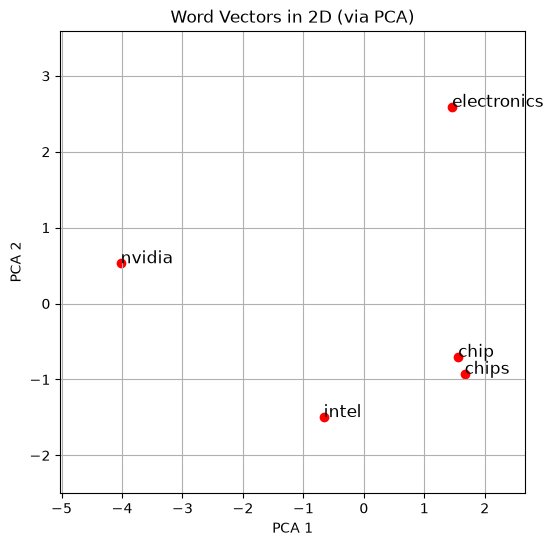

In [15]:
plot_vectors(['chip','chips','intel','electronics','nvidia'], glove_6b50d)

In the plot, *chip* and *chips* almost coincide: the singular and the plural occur in very similar contexts. *nvidia* lies far from them, in line with its low cosine similarity (keep in mind that 2 dimensions keep only part of the variance).

Below outputs similar words
to "baby" and "beautiful".


In [16]:
get_similar_tokens('baby', 3, glove_6b50d)

cosine sim=0.839: babies
cosine sim=0.800: boy
cosine sim=0.792: girl


In [17]:
get_similar_tokens('beautiful', 3, glove_6b50d)

cosine sim=0.921: lovely
cosine sim=0.893: gorgeous
cosine sim=0.830: wonderful


In [18]:
get_cosine_similarity('beautiful','switzerland',glove_6b50d)

Cosine similarity:  0.1123


*beautiful* and *switzerland* (0.11) are about as similar as two random words (see the comparison with random pairs above).

#### Similar or related?

Cosine similarity measures how similar the *contexts* of two words are, not whether the words mean the same. Words with opposite meanings often occur in the same contexts (*the water is hot / cold*), so their vectors can be as close as those of synonyms:

In [19]:
for a, b in [('good', 'great'), ('good', 'bad'), ('hot', 'warm'), ('hot', 'cold'), ('increase', 'decrease')]:
    print(f'{a} - {b}: {glove_6b50d.similarity(a, b):.2f}')

good - great: 0.80
good - bad: 0.80
hot - warm: 0.75
hot - cold: 0.80
increase - decrease: 0.89


A handy check: which word in a list does not fit? We compare every word with the average of all the words in the list and return the least similar one (in gensim, this is `doesnt_match`).

In [20]:
def get_odd_one_out(words, embed):
    vectors = torch.stack([torch.tensor(embed.get_vector(w, norm=True)) for w in words])  # length 1
    mean = vectors.mean(dim=0)
    cos = vectors @ mean / torch.norm(mean)  # cosine similarity of every word with the average
    return words[int(torch.argmin(cos))]

In [21]:
print(get_odd_one_out(['breakfast', 'cereal', 'dinner', 'lunch'], glove_6b50d))
print(get_odd_one_out(['paris', 'berlin', 'london', 'zurich', 'banana'], glove_6b50d))

cereal
banana


#### Why cosine similarity and not Euclidean distance?

The Euclidean distance $|\mathbf{a} - \mathbf{b}|$ depends on both the direction and the length of the vectors. For vectors of length 1, the two measures carry the same information, since $|\mathbf{a} - \mathbf{b}|^2 = 2 - 2\cos(\theta)$:

In [22]:
a, b = glove_6b50d['king'], glove_6b50d['queen']
print('For the words "king" and "queen":')
print('lengths:', np.round(np.linalg.norm(a), 2), np.round(np.linalg.norm(b), 2))
print('Euclidean distance:', np.round(np.linalg.norm(a - b), 3))
print('cosine similarity: ', np.round(glove_6b50d.similarity('king', 'queen'), 3))

a_unit, b_unit = a / np.linalg.norm(a), b / np.linalg.norm(b)  # normalise to length 1
print('length 1: |a - b|^2 =', np.round(np.linalg.norm(a_unit - b_unit) ** 2, 3),
      ' 2 - 2 cos =', np.round(2 - 2 * glove_6b50d.similarity('king', 'queen'), 3))

For the words "king" and "queen":
lengths: 5.37 5.19
Euclidean distance: 3.478
cosine similarity:  0.784
length 1: |a - b|^2 = 0.432  2 - 2 cos = 0.432


The lengths of GloVe vectors are not all the same: in GloVe, frequent words tend to have longer vectors than rare ones (on average 5.4 for the 100 most frequent words and 4.4 for words beyond frequency rank 100,000). This depends on the model; static vectors that are trained to be averaged into sentence vectors, for example, tend to give function words *smaller* norms.

How much does the choice matter? Here are the 5 nearest neighbours of three words according to both measures (GloVe 50d):

| Word | Cosine similarity | Euclidean distance |
|---|---|---|
| king | prince, queen, ii, emperor, son | prince, queen, uncle, ii, grandson |
| einstein | relativity, bohr, physics, heisenberg, freud | bohr, relativity, invented, freud, gottlieb |
| zurich | frankfurt, basel, amsterdam, switzerland, lausanne | basel, amsterdam, lausanne, bern, frankfurt |

For 200 random words among the 20,000 most frequent ones, on average 7 of the 10 nearest neighbours are the same. On the word similarity benchmarks introduced below, neither measure is clearly better (WordSim-353: 0.50 with cosine similarity vs 0.46 with Euclidean distance; SimLex-999: 0.26 vs 0.27).

So for GloVe, the choice changes the neighbours only a little. Cosine similarity is the usual choice because it ignores the vector length, which partly reflects word frequency, and because its values always lie between −1 and 1, so they are on the same scale for every pair of words. Many libraries also store vectors normalised to length 1 (in gensim: `get_normed_vectors()`); for such vectors, both measures give the same ranking.

### Word Analogy

Besides finding similar words,
we can also apply word vectors
to word analogy tasks.
For example,
“man”:“woman”::“son”:“daughter”
is the form of a word analogy:
“man” is to “woman” as “son” is to “daughter”.
Specifically,
the word analogy completion task
can be defined as:
for a word analogy
$a : b :: c : d$, given the first three words $a$, $b$ and $c$, find $d$.
Denote the vector of word $w$ by $\textrm{vec}(w)$.
To complete the analogy,
we will find the word
whose vector is most similar
to the result of $\textrm{vec}(c)+\textrm{vec}(b)-\textrm{vec}(a)$.

This method is called *3CosAdd*. We implement it below with our `knn` function; in gensim, the same is `most_similar(positive=[b, c], negative=[a])`. Note that the three input words are excluded from the answers (more on this below).

In [23]:
def get_analogy(token_a, token_b, token_c, embed):
    W = torch.tensor(embed.get_normed_vectors())  # all word vectors, scaled to length 1 (as in gensim)
    a, b, c = (torch.tensor(embed.get_vector(t, norm=True)) for t in (token_a, token_b, token_c))
    topk, cos = knn(W, b - a + c, 4)
    # the best match that is not one of the input words (at most 3 of the top 4 can be input words)
    for i in topk:
        token = embed.index_to_key[int(i)]
        if token not in (token_a, token_b, token_c):
            return token

In [24]:
print('Male-female analogy: woman - man + son =', get_analogy('man', 'woman', 'son', glove_6b50d))
print('Capital-country analogy: china - beijing + tokyo =', get_analogy('beijing', 'china', 'tokyo', glove_6b50d))
print('Comparative-superlative analogy: worst - bad + big =', get_analogy('bad', 'worst', 'big', glove_6b50d))

Male-female analogy: woman - man + son = daughter
Capital-country analogy: china - beijing + tokyo = japan
Comparative-superlative analogy: worst - bad + big = biggest


#### Visualising the vector arithmetic

In the plots below, the grey arrow goes from *a* to *b* (the relation). The dashed blue arrow adds the same shift to *c* and ends at **?** = vec(b) − vec(a) + vec(c). The orange point is the answer: the word closest to **?**.

In [25]:
# @title Function to plot an analogy
def plot_analogy(token_a, token_b, token_c, embed, ax):
    token_d = get_analogy(token_a, token_b, token_c, embed)
    a, b, c, d = (embed.get_vector(t, norm=True) for t in (token_a, token_b, token_c, token_d))  # length 1, as in most_similar
    query = b - a + c
    pca = PCA(n_components=2)
    A, B, C, D, Q = pca.fit_transform(np.stack([a, b, c, d, query]))

    ax.annotate('', xy=B, xytext=A, arrowprops=dict(arrowstyle='->', color='#52514e', lw=1.5))
    ax.annotate('', xy=Q, xytext=C, arrowprops=dict(arrowstyle='->', color='#2a78d6', lw=1.5, linestyle='--'))
    ax.scatter(*np.stack([A, B, C]).T, s=30, color='#52514e', zorder=3)
    ax.scatter(*Q, s=60, facecolors='white', edgecolors='#2a78d6', linewidths=1.5, zorder=3)
    ax.scatter(*D, s=40, color='#eb6834', zorder=4)
    # labels beyond the two ends of the arrows
    shift = (B - A) / np.linalg.norm(B - A)
    for point, label, color, side in [(A, token_a, '#52514e', -1), (B, token_b, '#52514e', 1),
                                      (C, token_c, '#52514e', -1), (Q, '?', '#2a78d6', 1)]:
        ax.annotate(label, point, xytext=side * 12 * shift, textcoords='offset points', ha='center', va='center', color=color)
    ax.annotate(token_d, D, xytext=(8, 0), textcoords='offset points', va='center', color='#eb6834')
    ax.margins(0.2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f'{token_a} : {token_b} :: {token_c} : {token_d}', loc='left')
    ax.text(0.99, 0.02, f'2D explained variance: {pca.explained_variance_ratio_.sum():.2f}',
            transform=ax.transAxes, ha='right', fontsize=8, color='#52514e')

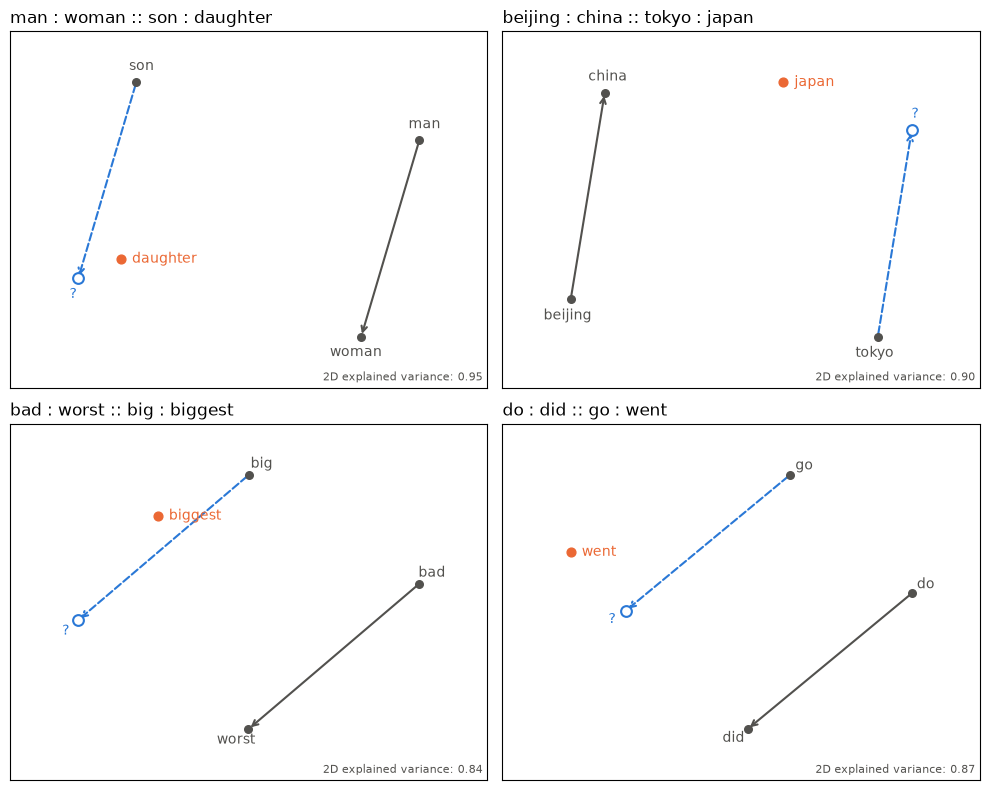

In [26]:
analogies = [('man', 'woman', 'son'), ('beijing', 'china', 'tokyo'), ('bad', 'worst', 'big'), ('do', 'did', 'go')]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for (token_a, token_b, token_c), ax in zip(analogies, axes.flat):
    plot_analogy(token_a, token_b, token_c, glove_6b50d, ax)
fig.tight_layout()
plt.show()

The answer never lies exactly at **?**: it is only the closest word, so analogies hold approximately. Within one relation, the shift is similar for many pairs of words, for example for countries and their capitals:

Explained variance in 2 dimensions:  0.48


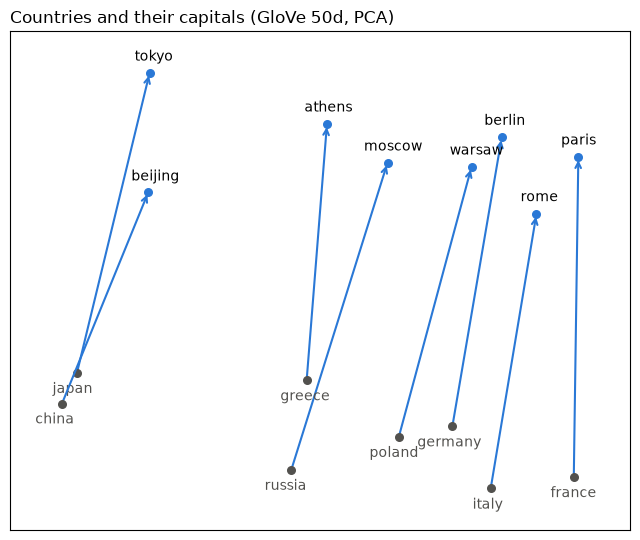

In [27]:
# @title Plot: countries and their capitals
pairs = [('germany', 'berlin'), ('france', 'paris'), ('italy', 'rome'), ('russia', 'moscow'),
         ('japan', 'tokyo'), ('china', 'beijing'), ('greece', 'athens'), ('poland', 'warsaw')]
words = [w for pair in pairs for w in pair]
pca = PCA(n_components=2)
points = dict(zip(words, pca.fit_transform(glove_6b50d[words])))
print('Explained variance in 2 dimensions: ', np.round(pca.explained_variance_ratio_.sum(), 2))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for country, capital in pairs:
    direction = (points[capital] - points[country]) / np.linalg.norm(points[capital] - points[country])
    ax.annotate('', xy=points[capital], xytext=points[country], arrowprops=dict(arrowstyle='->', color='#2a78d6', lw=1.5))
    ax.scatter(*points[country], s=30, color='#52514e', zorder=3)
    ax.scatter(*points[capital], s=30, color='#2a78d6', zorder=3)
    # labels beyond the two ends of the arrow
    ax.annotate(country, points[country], xytext=-12 * direction, textcoords='offset points', ha='center', va='center', color='#52514e')
    ax.annotate(capital, points[capital], xytext=12 * direction, textcoords='offset points', ha='center', va='center')
ax.set_xticks([])
ax.set_yticks([])
ax.margins(0.1)  # room for the labels at the edges
ax.set_title('Countries and their capitals (GloVe 50d, PCA)', loc='left')
fig.tight_layout()
plt.show()

A note on these plots: they show only 2 of the 50 dimensions. The explained variance printed with each plot says how much of the spread of the points the picture keeps. With a few words it is easily high (even 4 random words give about 0.8; our analogies 0.84–0.95), with the 16 words of the capitals plot it is about half, and for the 10,000 most frequent words only 0.13. So such plots are illustrations; all similarities are computed in the full 50 dimensions.

#### What if the input words are not excluded?

Without the exclusion, the word closest to vec(b) − vec(a) + vec(c) is often one of the input words. Here is the same computation as in `get_analogy`, but keeping all words:

In [28]:
W = torch.tensor(glove_6b50d.get_normed_vectors())
for a, b, c in [('man', 'woman', 'king'), ('good', 'better', 'bad')]:
    vec_a, vec_b, vec_c = (torch.tensor(glove_6b50d.get_vector(w, norm=True)) for w in (a, b, c))
    topk, cos = knn(W, vec_b - vec_a + vec_c, 3)
    print(f'{a} : {b} :: {c} : ?', [(glove_6b50d.index_to_key[int(i)], round(float(s), 2)) for i, s in zip(topk, cos)])

man : woman :: king : ? [('king', 0.89), ('queen', 0.85), ('throne', 0.77)]


good : better :: bad : ? [('bad', 0.93), ('worse', 0.9), ('too', 0.83)]


*man : woman :: king : queen*, the most famous example, only works because *king* itself is excluded. The examples above were chosen because they work; the analogy benchmark below shows how often analogies work in general.

Analogies also reflect how words are used in the training texts, not facts. What is the capital of Switzerland?

In [29]:
print(get_analogy('france', 'paris', 'switzerland', glove_6b50d))
print(get_analogy('france', 'paris', 'switzerland', glove_6b100d))

zurich


zurich


## Evaluating Word Embeddings

How do we know whether word embeddings are good? There are two kinds of evaluation:

* *Intrinsic* evaluation tests the vectors directly: we look at the nearest neighbours of some words, or use small tasks with known answers, such as word similarity ratings and analogy questions. It is fast and needs no further model.
* *Extrinsic* evaluation uses the vectors as input for a downstream task (e.g. text classification) and measures how much they help. This is what matters in the end, but it is slower and depends on the task.

### Inspecting nearest neighbours

The simplest check is to look at the nearest neighbours of some words: it shows where a model works and where it does not. It helps to look at both frequent and rare words. Below are the neighbours of the words with frequency ranks 500, 5,000, 50,000 and 150,000:

In [30]:
for rank in [500, 5000, 50000, 150000]:
    word = glove_6b50d.index_to_key[rank]
    print(f'rank {rank:>7,}: {word:<12} ->', [w for w, _ in glove_6b50d.most_similar(word, topn=5)])

rank     500: working      -> ['work', 'worked', 'well', 'doing', 'interested']
rank   5,000: technique    -> ['techniques', 'method', 'methods', 'experimental', 'experiment']


rank  50,000: bec          -> ['sasana', 'tero', 'michalka', 'tooting', 'bega']
rank 150,000: cryogenics   -> ['humanplasma', 'level-4', 'graphology', 'daresbury', 'cheminformatics']


The neighbours of frequent words make sense, while those of rare words are mostly noise: a word seen in only a few contexts gets a poorly estimated vector.

### Word similarity benchmarks

gensim comes with three standard intrinsic test sets (two for word similarity, one for analogies), so no download is needed. *WordSim-353* (353 word pairs) and *SimLex-999* (999 pairs) contain similarity ratings by humans on a scale from 0 to 10. We compute the cosine similarity of each pair and report the [Spearman correlation](https://en.wikipedia.org/wiki/Spearman%27s_rank_correlation_coefficient) with the human ratings. It only compares how the pairs are *ranked*, not the values themselves, so it does not matter that cosine similarities and human ratings are on different scales (1: same ranking as the humans, 0: no relation).

The two datasets differ in what they call similar. WordSim-353 also gives high scores to related words (*cup – coffee*: 6.58), while SimLex-999 only rates words with similar meanings high; related words and antonyms get low scores (*old – new*: 1.58).

In [31]:
for name, embed in [('50d', glove_6b50d), ('100d', glove_6b100d)]:
    wordsim = embed.evaluate_word_pairs(datapath('wordsim353.tsv'))[1].statistic  # [1]: Spearman correlation
    simlex = embed.evaluate_word_pairs(datapath('simlex999.txt'))[1].statistic
    print(f'GloVe {name}: WordSim-353 {wordsim:.2f}, SimLex-999 {simlex:.2f}')

GloVe 50d: WordSim-353 0.50, SimLex-999 0.26


GloVe 100d: WordSim-353 0.53, SimLex-999 0.30


Both models agree much better with the humans on WordSim-353 than on SimLex-999: the vectors capture which words are *related* (occur in similar contexts) more than which words *mean the same*, as we saw with the antonyms above. The 100-dimensional vectors are slightly better on both.

### Analogy benchmark

The *Google analogy test set* ([Mikolov et al., 2013](https://arxiv.org/abs/1301.3781)) contains 19,544 questions of the form *a : b :: c : ?* in 5 semantic categories (e.g. capitals, currencies, family relations) and 9 syntactic ones (e.g. opposites such as *possible : impossible*, plurals, past tense). An answer counts as correct only if the top-ranked word (excluding *a*, *b* and *c*) is exactly the expected one.

In [32]:
def accuracy(section):
    return len(section['correct']) / (len(section['correct']) + len(section['incorrect']))

analogy_results = {}
for name, embed in [('50d', glove_6b50d), ('100d', glove_6b100d)]:
    analogy_results[name] = embed.evaluate_word_analogies(datapath('questions-words.txt'))[1]  # one entry per category, the total last
    print(f'GloVe {name}: {accuracy(analogy_results[name][-1]):.0%} of the questions answered correctly')

GloVe 50d: 46% of the questions answered correctly


GloVe 100d: 63% of the questions answered correctly


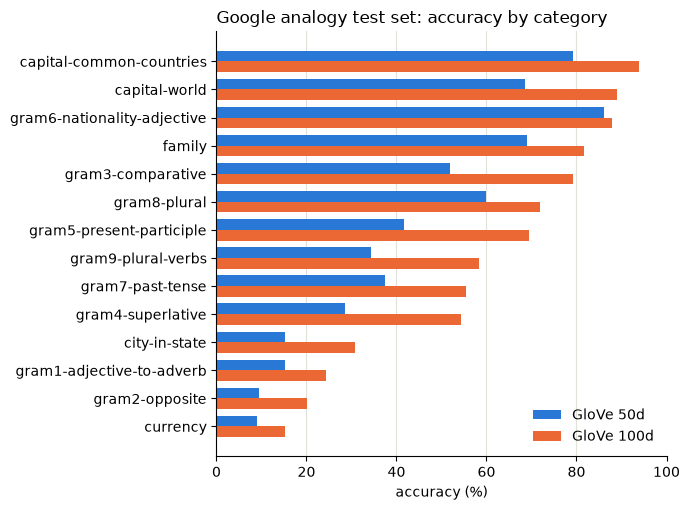

In [33]:
# @title Plot: analogy accuracy by category
categories = np.array([s['section'] for s in analogy_results['50d'][:-1]])
acc_50d = np.array([accuracy(s) * 100 for s in analogy_results['50d'][:-1]])
acc_100d = np.array([accuracy(s) * 100 for s in analogy_results['100d'][:-1]])
order = np.argsort(acc_100d)
y = np.arange(len(categories))

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(y + 0.19, acc_50d[order], height=0.38, color='#2a78d6', label='GloVe 50d')
ax.barh(y - 0.19, acc_100d[order], height=0.38, color='#eb6834', label='GloVe 100d')
ax.set_yticks(y, categories[order])
ax.set_xlim(0, 100)
ax.set_xlabel('accuracy (%)')
ax.xaxis.grid(True, color='#e1e0d9')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Google analogy test set: accuracy by category', loc='left')
fig.tight_layout()
plt.show()

The 100-dimensional vectors answer clearly more questions correctly. Accuracy is very uneven across categories: capitals and nationality adjectives work well, while currencies and opposites mostly fail. Two of the four examples above come from categories where most questions fail with 50 dimensions (superlatives and past tense).

### Extrinsic evaluation

In the end, embeddings are a means to an end: the real test is how much they help in a downstream task, e.g. as input features for a text classifier. Intrinsic scores and downstream performance do not always agree, so benchmarks are a quick first check, not the final word.

## Limitations

### One vector per word

A static embedding has exactly one vector per word form, so all senses of a word are mixed in this vector, weighted by how often each sense occurs in the training texts. In news and Wikipedia text, *chip* (as we saw above) and *apple* are mostly about computers and *bank* about finance, so the other senses hardly show up among the neighbours. The vector of *python* mixes the snake, Monty Python and the programming language.

In [34]:
for word in ['bank', 'apple', 'python', 'java']:
    print(f'{word:<7} ->', [w for w, _ in glove_6b50d.most_similar(word, topn=7)])
print(f"The odd one out in ['python', 'java', 'ruby', 'snake'] is: {get_odd_one_out(['python', 'java', 'ruby', 'snake'], glove_6b50d)}")

bank    -> ['banks', 'securities', 'banking', 'investment', 'exchange', 'financial', 'credit']
apple   -> ['blackberry', 'chips', 'iphone', 'microsoft', 'ipad', 'pc', 'ipod']
python  -> ['reticulated', 'spamalot', 'php', 'owl', 'mouse', 'reticulatus', 'perl']
java    -> ['semarang', 'surabaya', 'applets', 'remote', 'applet', 'api', 'wii']
The odd one out in ['python', 'java', 'ruby', 'snake'] is: java


The mixed vectors also confuse `get_odd_one_out`: it picks *java* (here mostly an island and a programming language) rather than *snake*. Contextual embeddings, e.g. from transformer models, avoid this by computing a separate vector for every occurrence of a word in its sentence.

### Similar contexts, opposite meanings

As we saw above, antonyms such as *hot* and *cold* get similar vectors because they occur in the same contexts. For a task such as sentiment analysis, this is a problem: *good – bad* (0.80) is as similar as *good – great* (0.80).

### A fixed vocabulary, frozen in time

The vocabulary is fixed when the model is trained. Words that did not occur in the training texts (from 2014 for glove.6B) have no vector, and looking them up raises a `KeyError`. glove.6B is also lowercased, so words must be looked up in lowercase. Words that are known keep the meaning they had in the training texts.

In [35]:
for word in ['covid', 'chatgpt', 'brexit', 'selfie', 'Zurich', 'zurich']:
    print(f'{word:<8} in vocabulary: {word in glove_6b50d.key_to_index}')

covid    in vocabulary: False
chatgpt  in vocabulary: False
brexit   in vocabulary: False
selfie   in vocabulary: False
Zurich   in vocabulary: False
zurich   in vocabulary: True


In [36]:
for word in ['coronavirus', 'zoom']:
    print(f'{word:<11} ->', [w for w, _ in glove_6b50d.most_similar(word, topn=5)])

coronavirus -> ['hantavirus', 'norovirus', 'irukandji', 'carcinogen', 'malady']
zoom        -> ['10x', 'viewfinder', 'slr', '35mm', 'lenses']


### A partial remedy: subword vectors (fastText)

fastText learns vectors for character n-grams (for *where*: *<wh, whe, her, ere, re>*) and builds the vector of a word as the sum of its n-gram vectors. It can therefore give vectors to words it has never seen, such as new word forms, rare words and typos. It does not help with new meanings of known words.

### Biases from the training data

Embeddings reproduce the associations in their training texts, including stereotypes ([Bolukbasi et al., 2016](https://arxiv.org/abs/1607.06520)). Below, we complete two analogies and plot some occupation words along a *she*–*he* direction. A single pair is not a reliable direction, since the differences of different pairs only partly agree; we therefore average the differences of 8 pairs (*he – she*, *man – woman*, *his – her*, *father – mother*, *boy – girl*, *king – queen*, *son – daughter*, *brother – sister*).

In [37]:
print(get_analogy('he', 'she', 'doctor', glove_6b50d))
print(get_analogy('father', 'doctor', 'mother', glove_6b50d))

nurse
nurse


Average cosine similarity between the 8 pair differences: 0.71


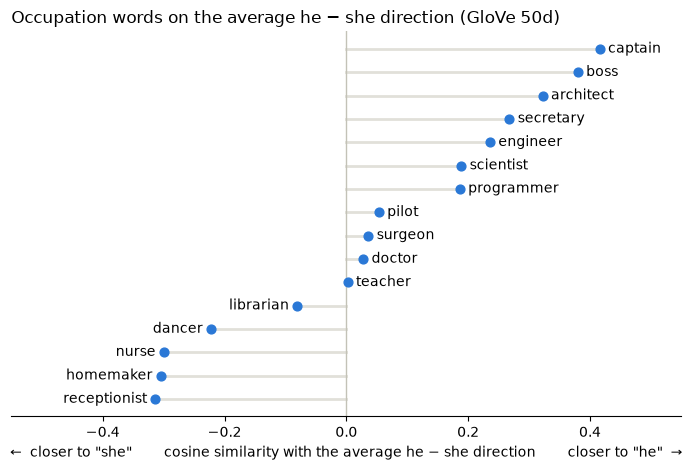

In [38]:
# @title Plot: occupation words on the average he − she direction
pairs = [('he', 'she'), ('man', 'woman'), ('his', 'her'), ('father', 'mother'),
         ('boy', 'girl'), ('king', 'queen'), ('son', 'daughter'), ('brother', 'sister')]
differences = np.array([glove_6b50d.get_vector(m, norm=True) - glove_6b50d.get_vector(f, norm=True) for m, f in pairs])
unit_differences = differences / np.linalg.norm(differences, axis=1, keepdims=True)
agreement = unit_differences @ unit_differences.T
print('Average cosine similarity between the 8 pair differences:', np.round(agreement[np.triu_indices(len(pairs), k=1)].mean(), 2))
gender_direction = differences.mean(axis=0)
gender_direction /= np.linalg.norm(gender_direction)
occupations = ['nurse', 'receptionist', 'homemaker', 'dancer', 'librarian', 'doctor', 'teacher', 'surgeon',
               'pilot', 'programmer', 'scientist', 'engineer', 'secretary', 'architect', 'boss', 'captain']
scores = sorted((glove_6b50d.get_vector(w, norm=True) @ gender_direction, w) for w in occupations)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.axvline(0, color='#c3c2b7', lw=1)
for i, (score, word) in enumerate(scores):
    ax.plot([0, score], [i, i], color='#e1e0d9', lw=2, zorder=1)
    ax.scatter(score, i, s=40, color='#2a78d6', zorder=3)
    ax.annotate(word, (score, i), xytext=(6 if score >= 0 else -6, 0), textcoords='offset points',
                va='center', ha='left' if score >= 0 else 'right')
ax.set_xlim(-0.55, 0.55)
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.set_xlabel('←  closer to "she"        cosine similarity with the average he − she direction        closer to "he"  →')
ax.set_title('Occupation words on the average he − she direction (GloVe 50d)', loc='left')
fig.tight_layout()
plt.show()

In [39]:
get_similar_tokens('secretary', 5, glove_6b50d)

cosine sim=0.884: deputy
cosine sim=0.840: vice
cosine sim=0.831: affairs
cosine sim=0.827: general
cosine sim=0.810: president


*secretary* lies on the *he* side, probably because in news text it mostly refers to ministers (*Secretary of State*), as its neighbours show: here, bias and polysemy mix. Models that use such vectors as input can inherit these associations.

## Summary

* Static word embeddings (word2vec, GloVe, fastText) assign one fixed vector to each word. They are learned from co-occurrence: words that occur in similar contexts get similar vectors.
* Cosine similarity finds related words, and differences between vectors capture some relations between words (analogies), much better for some relations than for others.
* To check the quality of word embeddings, inspect the neighbours of frequent and rare words and use intrinsic benchmarks such as WordSim-353, SimLex-999 and the Google analogy test set. In the end, what matters is how much they help in a downstream task.
* Limitations: one vector per word (all senses mixed), antonyms close to each other, a fixed vocabulary frozen at training time, and biases from the training data.


## Questions for discussion

1. Why do antonyms such as *hot* and *cold* get similar vectors? What kind of training signal could separate them?
1. When the vocabulary is extremely large, how can we find similar words or complete a word analogy faster?
1. Which of the limitations above disappear if every occurrence of a word gets its own vector, computed from its sentence? Which remain?